# Team Information

- **Yara Muhammad Al Muzhar** — Student ID: 448815896
- **Maram Al-sunaidi** — Student ID: 448815727
- **Thikra Ali Alshahrani** — Student ID: 448815965
- **Yomn Ali Alsultan** — Student ID: 448816841

- **Course:** Practical Data Science
- **Instructor:** Anado Havli


# Saudi Arabia Population Analysis

## Project Information

- **Project title:** Population Distribution by Administrative Region and Gender in Saudi Arabia (2010–2024)
- **Course:** Practical Data Science
- **Data question:** How has the estimated population changed by gender over time, and how do Saudi administrative regions compare in the latest available year?
- **Dataset:** Population by Administrative Region and Gender
- **Country:** Saudi Arabia
- **Coverage:** 2010–2024
- **Data source:** KAPSARC Data Portal, based on annual data from the Saudi Central Bank (SAMA)
- **Analysis type:** Descriptive data analysis
- **Expected outputs:** Cleaned data, aggregated tables, three visualizations, and a JSON summary

This notebook downloads the real dataset automatically, checks the data structure and quality, cleans and transforms the records, performs aggregations, saves outputs, and creates three visualizations with interpretation prompts. Run the cells from top to bottom.


This cell imports the Python libraries and defines the project folders and visualization settings used throughout the notebook.


In [ ]:
# Saudi Arabia Population Analysis
# Topic: Population distribution by administrative region and gender (2010-2024)

from pathlib import Path
import io
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


This cell defines the source URL, project directories, and plotting style. It also creates the folders needed to save data and outputs.


## 1. Project configuration


This cell downloads the real population dataset from the KAPSARC Data Portal and loads it into a pandas DataFrame.


In [ ]:
DATA_URL = (
    "https://datasource.kapsarc.org/api/explore/v2.1/catalog/datasets/"
    "saudi-arabia-population-by-administrative-region-nationality-and-sex/"
    "exports/csv?lang=en&timezone=UTC"
)
BASE_DIR = Path.cwd()
# If the notebook is opened from the notebooks/ folder, use the project root.
if BASE_DIR.name == "notebooks":
    BASE_DIR = BASE_DIR.parent
DATA_DIR = BASE_DIR / "data"
OUTPUT_DIR = BASE_DIR / "outputs"
FIGURE_DIR = OUTPUT_DIR / "figures"
DATA_DIR.mkdir(exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["axes.titleweight"] = "bold"


This cell performs the next step of the data analysis workflow and displays or saves the resulting output.


## 2. Download the real dataset


This cell performs the next step of the data analysis workflow and displays or saves the resulting output.


In [ ]:
raw_path = DATA_DIR / "saudi_population_raw.csv"
response = requests.get(DATA_URL, timeout=60)
response.raise_for_status()
raw_path.write_bytes(response.content)
print(f"Downloaded: {raw_path} ({raw_path.stat().st_size:,} bytes)")

# The KAPSARC export is a semicolon-separated CSV with a UTF-8 BOM.
raw = pd.read_csv(raw_path, sep=";", encoding="utf-8-sig", low_memory=False)
print("Raw shape:", raw.shape)
print("Raw columns:", raw.columns.tolist())
raw.head()


Downloaded: /content/data/saudi_population_raw.csv (504,791,594 bytes)
Raw shape: (630, 6)
Raw columns: ['date', 'region', 'gender', 'value', 'geo_shape', 'geo_point_2d']


,date,region,gender,value,geo_shape,geo_point_2d
0,2024,Asir,Female,870944,"{""coordinates"": [[[[43.26609452500003, 20.8026...","19.138215843088204, 42.94200878026759"
1,2024,Hail,Total,814935,"{""coordinates"": [[[41.61404776400008, 29.20787...","27.429485105042442, 41.43623362551672"
2,2024,Jazan,Female,641632,"{""coordinates"": [[[[42.23012930300007, 18.0408...","17.20610863636406, 42.65323379535679"
3,2024,Al-Madinah,Female,913726,"{""coordinates"": [[[[37.77604391400007, 27.4136...","24.843372659914383, 39.57889995543745"
4,2024,Al-Jawf,Total,643372,"{""coordinates"": [[[37.98419985800007, 31.74987...","29.980192590724698, 39.541773243495875"


This cell checks the dataset dimensions, column names, data types, missing values, and duplicate records before cleaning.


## 3. Data understanding


This cell displays data quality information so we can understand the structure of the raw dataset before transformation.


In [ ]:
print("\nData types before cleaning:")
print(raw.dtypes)
print("\nMissing values before cleaning:")
print(raw.isna().sum())
print("\nDuplicate rows before cleaning:", raw.duplicated().sum())

# Keep analytical columns. geo_shape and geo_point_2d are geographic metadata,
# not needed for this descriptive analysis.
required_columns = ["date", "region", "gender", "value"]
missing_required = [c for c in required_columns if c not in raw.columns]
if missing_required:
    raise ValueError(f"Missing expected columns: {missing_required}")

df = raw[required_columns].copy()
df = df.rename(columns={"date": "year", "value": "population"})
df["year"] = pd.to_numeric(df["year"], errors="coerce")
df["population"] = pd.to_numeric(df["population"], errors="coerce")
df["region"] = df["region"].astype("string").str.strip()
df["gender"] = df["gender"].astype("string").str.strip().str.title()
# The source export includes aggregate rows labelled Total. They must not be
# added to regional or gender totals because they would double-count records.
df = df[(df["region"] != "Total") & (df["gender"] != "Total")]



Data types before cleaning:
date             int64
region          object
gender          object
value            int64
geo_shape       object
geo_point_2d    object
dtype: object

Missing values before cleaning:
date             0
region           0
gender           0
value            0
geo_shape       45
geo_point_2d    45
dtype: int64

Duplicate rows before cleaning: 0


This cell selects the analytical columns, converts data types, removes aggregate Total rows, handles invalid records, removes duplicates, and saves the cleaned dataset.


## 4. Cleaning and error handling


This cell checks missing values after conversion and applies the final cleaning rules to prepare reliable records for analysis.


In [ ]:
print("\nMissing values after type conversion:")
print(df.isna().sum())

before = len(df)
df = df.dropna(subset=["year", "region", "gender", "population"])
df = df[df["population"] >= 0]
df["year"] = df["year"].astype(int)
df["population"] = df["population"].astype(int)
df = df.drop_duplicates().sort_values(["year", "region", "gender"]).reset_index(drop=True)
print(f"Rows removed during cleaning: {before - len(df)}")
print("Clean shape:", df.shape)
print("Years:", df["year"].min(), "to", df["year"].max())
print("Regions:", df["region"].nunique())
print("Genders:", df["gender"].unique().tolist())

# Save final cleaned dataset.
clean_path = DATA_DIR / "saudi_population_clean.csv"
df.to_csv(clean_path, index=False, encoding="utf-8-sig")
print("Saved:", clean_path)



Missing values after type conversion:
year          0
region        0
gender        0
population    0
dtype: int64
Rows removed during cleaning: 0
Clean shape: (390, 4)
Years: 2010 to 2024
Regions: 13
Genders: ['Female', 'Male']
Saved: /content/data/saudi_population_clean.csv


This cell creates summary tables by year, gender, and region, calculates gender shares, and saves the aggregated results as CSV files.


## 5. Aggregation and derived measures


This cell calculates the total population for each year and gender and saves the trend table for later use.


In [ ]:
# Total population by year and gender.
trend = (
    df.groupby(["year", "gender"], as_index=False)["population"]
      .sum()
      .sort_values(["year", "gender"])
)
trend.to_csv(OUTPUT_DIR / "population_trend_by_gender.csv", index=False, encoding="utf-8-sig")

# Total population by region in the latest available year.
latest_year = int(df["year"].max())
latest = df[df["year"] == latest_year].copy()
region_totals = (
    latest.groupby("region", as_index=False)["population"]
          .sum()
          .sort_values("population", ascending=False)
)
region_totals.to_csv(OUTPUT_DIR / "latest_population_by_region.csv", index=False, encoding="utf-8-sig")

# Gender share by region in the latest year.
latest_pivot = latest.pivot_table(
    index="region", columns="gender", values="population", aggfunc="sum", fill_value=0
)
latest_pivot["Total"] = latest_pivot.sum(axis=1)
for gender in ["Female", "Male"]:
    if gender in latest_pivot.columns:
        latest_pivot[f"{gender}_share_pct"] = latest_pivot[gender] / latest_pivot["Total"] * 100
latest_pivot = latest_pivot.sort_values("Total", ascending=False)
latest_pivot.to_csv(OUTPUT_DIR / "latest_gender_breakdown_by_region.csv", encoding="utf-8-sig")

print(f"\nLatest available year: {latest_year}")
print("Top regions:")
print(region_totals.head())



Latest available year: 2024
Top regions:
            region  population
11          Riyadh     9541926
8           Makkah     8763473
5   Eastern Region     5673507
2       Al-Madinah     2329961
4             Asir     2198278


This cell creates the first visualization, showing how the estimated population changes over time for females and males.


## 6. Visualization 1: national trend by gender


This cell formats and saves the first line chart showing the national population trend by gender.


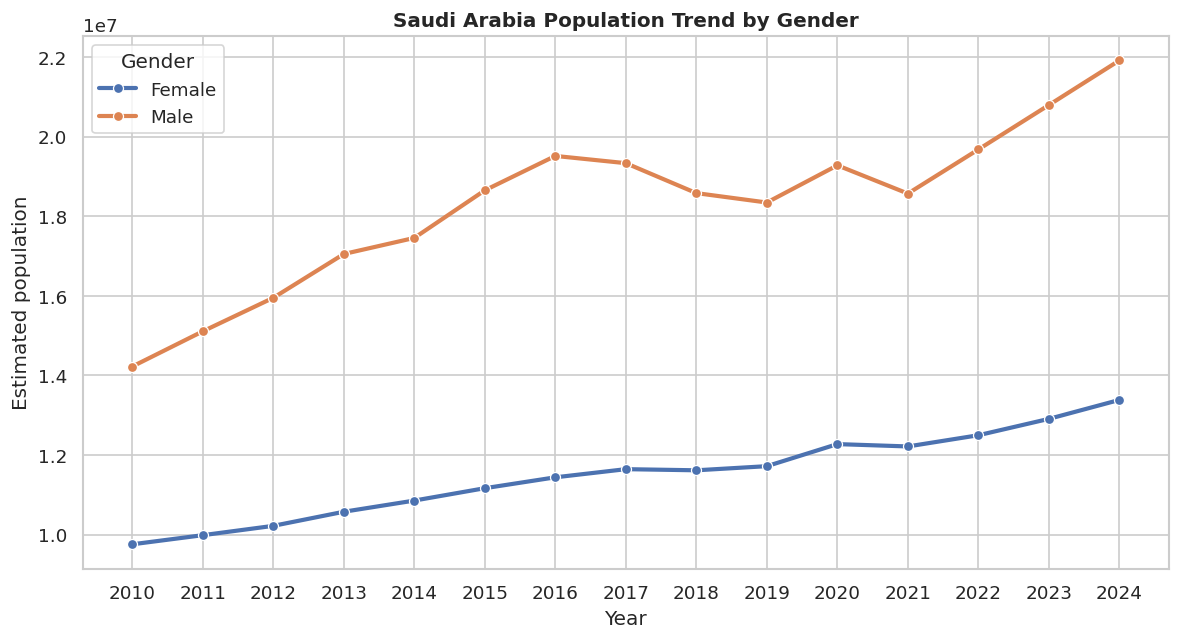

In [ ]:
plt.figure(figsize=(10, 5.5))
sns.lineplot(data=trend, x="year", y="population", hue="gender", marker="o", linewidth=2.5)
plt.title("Saudi Arabia Population Trend by Gender")
plt.xlabel("Year")
plt.ylabel("Estimated population")
plt.xticks(sorted(trend["year"].unique()))
plt.legend(title="Gender")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "01_population_trend_by_gender.png", bbox_inches="tight")
plt.show()


This cell creates the second visualization, comparing the population of Saudi administrative regions in the latest available year.


## 7. Visualization 2: regional comparison


This cell formats and saves the regional population bar chart.


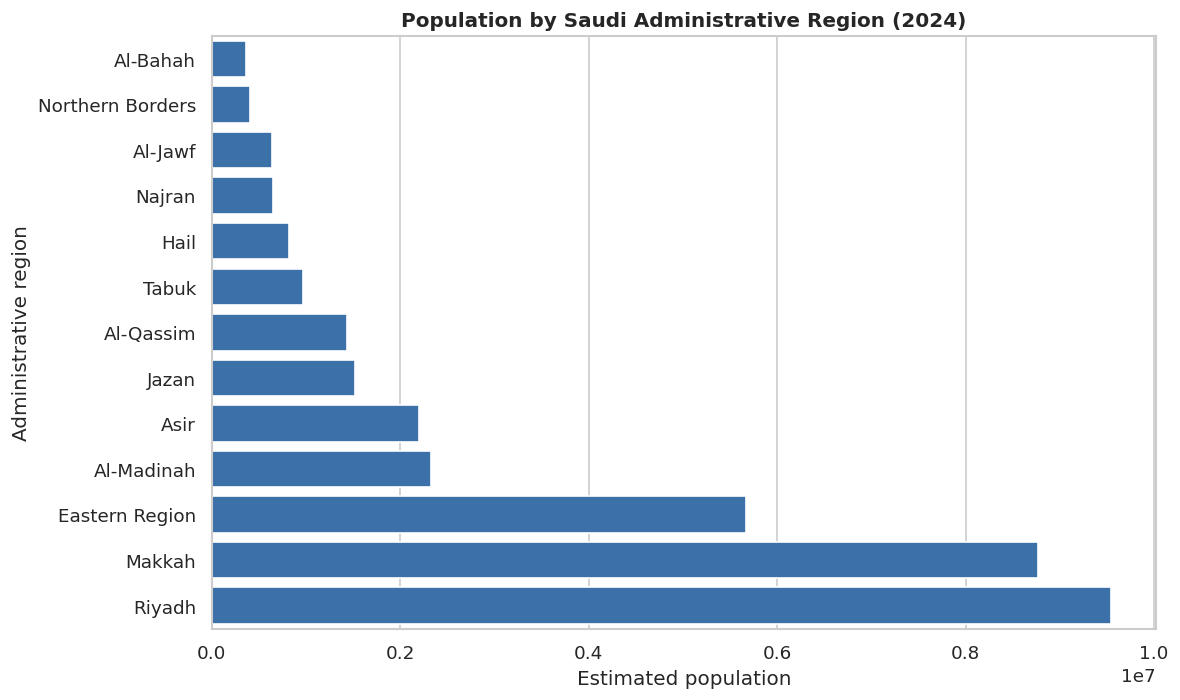

In [ ]:
plt.figure(figsize=(10, 6))
plot_data = region_totals.sort_values("population", ascending=True)
sns.barplot(data=plot_data, x="population", y="region", color="#2a6fbb")
plt.title(f"Population by Saudi Administrative Region ({latest_year})")
plt.xlabel("Estimated population")
plt.ylabel("Administrative region")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "02_population_by_region_latest_year.png", bbox_inches="tight")
plt.show()


This cell creates the third visualization, showing the percentage composition of females and males in each region.


## 8. Visualization 3: gender composition by region


This cell prepares the gender-share table and saves the stacked bar chart for regional gender composition.


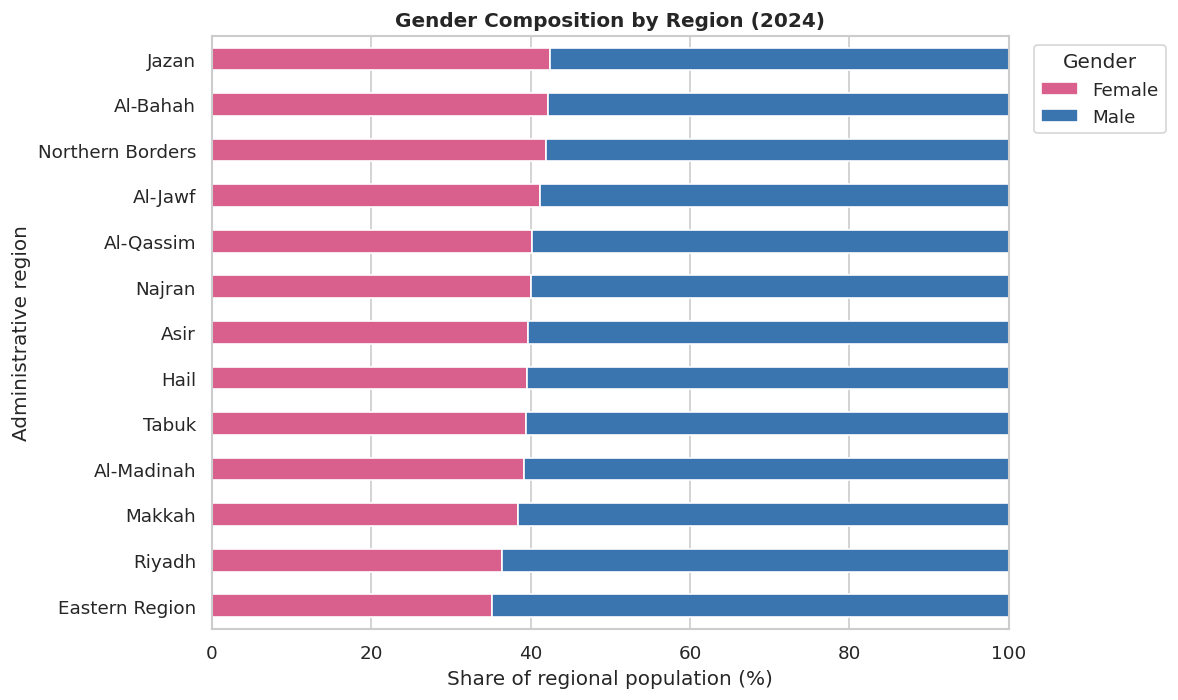

In [ ]:
share_columns = [c for c in ["Female_share_pct", "Male_share_pct"] if c in latest_pivot.columns]
share_plot = latest_pivot[share_columns].copy()
share_plot.columns = [c.replace("_share_pct", "") for c in share_plot.columns]
share_plot = share_plot.sort_values("Female" if "Female" in share_plot else share_plot.columns[0])
ax = share_plot.plot(kind="barh", stacked=True, figsize=(10, 6), color=["#d95f8d", "#3b75af"])
ax.set_title(f"Gender Composition by Region ({latest_year})")
ax.set_xlabel("Share of regional population (%)")
ax.set_ylabel("Administrative region")
ax.legend(title="Gender", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.xlim(0, 100)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "03_gender_composition_by_region.png", bbox_inches="tight")
plt.show()


This cell creates a concise JSON summary containing key values that can be used later in the written report and presentation.


## 9. Reproducible summary for the report


This cell saves the main project statistics, such as the latest year, number of regions, total population, and largest region.


In [ ]:
summary = {
    "source": "KAPSARC Data Portal / Saudi Central Bank (SAMA)",
    "latest_year": latest_year,
    "number_of_years": int(df["year"].nunique()),
    "number_of_regions": int(df["region"].nunique()),
    "total_population_latest_year": int(latest["population"].sum()),
    "largest_region_latest_year": str(region_totals.iloc[0]["region"]),
    "largest_region_population": int(region_totals.iloc[0]["population"]),
}
with open(OUTPUT_DIR / "summary.json", "w", encoding="utf-8") as f:
    import json
    json.dump(summary, f, ensure_ascii=False, indent=2)
print("\nSummary for report:")
print(json.dumps(summary, ensure_ascii=False, indent=2))

# Suggested interpretation prompts (write the final narrative after running).
print("\nInterpretation prompts:")
print("1) Describe the overall change in population by gender across the years.")
print("2) Identify the regions with the largest and smallest populations in the latest year.")
print("3) Compare the gender shares across regions and note whether they are similar or different.")



Summary for report:
{
  "source": "KAPSARC Data Portal / Saudi Central Bank (SAMA)",
  "latest_year": 2024,
  "number_of_years": 15,
  "number_of_regions": 13,
  "total_population_latest_year": 35300280,
  "largest_region_latest_year": "Riyadh",
  "largest_region_population": 9541926
}

Interpretation prompts:
1) Describe the overall change in population by gender across the years.
2) Identify the regions with the largest and smallest populations in the latest year.
3) Compare the gender shares across regions and note whether they are similar or different.
